# **Maestría en Inteligencia Artificial Aplicada**

## **Curso: Inteligencia Artificial y Aprendizaje Automático**

**Tecnológico de Monterrey**

**Prof Luis Eduardo Falcón Morales**

### **Actividad de Modelos basados en Árboles**

* **Nombre:** Miguel Labra Lorenzana

* **Matrícula:** A01363726

# **Introducción: Auditoría de modelos de riesgo crediticio basados en Árboles**



### **Contexto del problema:**

* Una startup de tecnología financiera (fintech) llamada CrediNova busca fortalecer su proceso de evaluación de riesgo para créditos de consumo. Actualmente, la empresa recibe miles de solicitudes cada mes y desea anticipar cuáles clientes podrían incumplir sus obligaciones financieras durante los próximos 90 días.

* Dichos clientes ya tienen una relación vigente con la institución, con la cual ya poseen uno o más productos financieros activos. Se desea predecir, al momento de la evaluación (para otorgar o revisar un crédito), cuáles de dichos clientes caerán en incumplimiento de algunos de sus pagos durante los siguientes 90 días.

* Un analista junior del área de ciencia de datos bajo su propia iniciativa desarrolló la solución que se encuentra en este cuaderno de Jupyter, la cual está basada en modelos de árboles. Se dio a la tarea de conjuntar la información histórica con diversas áreas de la empresa y generar la base de datos que se encuentra en el archivo "fintech_default_risk.csv". Dicho archivo lo encuentras en Canvas.  

* Los resultados que se obtienen al ejecutar el código se ven bastante prometedores, tan es así, que el CEO desea autorizar su despliegue a producción lo antes posible. Sin embargo, la dirección de riesgos desea realizar antes una última validación de la propuesta. Siendo tú un científico de datos senior, te encargan realizar una auditoría forense de este cuaderno.  

* En particular, se espera que cumplas con los siguientes objetivos:

  * Puedes modificar el cuaderno (celdas de texto y código) tanto como lo consideres necesario, salvo donde se te indique.

  * Identificar y documentar al menos 6 errores conceptuales o metodológicos en la propuesta actual.
  
  * Detectar posibles fuentes de fuga de información (data leakage) tanto en los datos como en el proceso de ajuste y entrenamiento de los modelos.

  * Justificar el uso de la métrica, y en su caso, evaluar la pertinencia de proponer y usar otras métricas.

  * Identificar evidencia de sub o sobreentrenamiento con respecto a la métrica en cuestión.

  * Analizar el impacto de la selección del umbral de clasificación sobre los resultados del negocio.

  * Decidir cuál de los 3 modelos de árboles consideras el más adecuado para desplegar en producción.

  * Identificar los 3 o 4 factores más importantes del mejor modelo obtenido. Explicar sus significados en el contexto de negocio.

  * Realizar un reporte del resultado de la auditoría forense comprensible para los tomadores de decisiones. En particular, indicar si el modelo se puede desplegar en producción como lo propone el analista junior, o cuál serían en dado caso las recomendaciones.

  * Reportar las herramientas de IA generativa (LLMs) utilizadas como apoyo para la auditoría.
  

### **Descripción del negocio:**

* Cada vez que una solicitud de crédito es aprobada:
   * Si el cliente paga correctamente, la empresa obtiene una utilidad neta estimada de $100 USD.

   * Si el cliente entra en incumplimiento, la empresa enfrenta una pérdida promedio estimada de $500 USD.

* Por este motivo, el objetivo no consiste únicamente en maximizar métricas estadísticas, sino en maximizar el valor económico esperado para la organización. Por ello, como parte del análisis, también deberás estimar:
   * La utilidad esperada utilizando el umbral estándar de clasificación (0.5).

   * La utilidad esperada utilizando un umbral optimizado.
   
   * El impacto económico estimado por cada 10,000 solicitudes evaluadas.

### **Cómo está organizada esta auditoría**

* **Parte I – Revisión del cuaderno original.** El código del analista se conserva tal cual (para poder reproducir lo que vio la dirección), pero después de cada bloque problemático se agrega una celda **Hallazgo** con el error encontrado y su evidencia.
* **Parte II – Solución corregida.** Se rehace el flujo completo sin fugas de información, con métricas adecuadas, ajuste de hiperparámetros por validación cruzada, selección del umbral sin tocar el conjunto de prueba y análisis económico con la proporción real de incumplimiento.
* **Conclusiones.** Reporte para el CEO y conclusiones finales de la actividad.

Se respeta en todo momento `RANDOM_STATE = 11`.

# **PARTE I – Revisión del cuaderno original**

# **Cargando y conociendo la información**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from imblearn.over_sampling import SMOTE

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import shap


RANDOM_STATE = 11   # No modificar el valor de esta semilla.
                    # Siempre que aparezca esta semilla, seguirla utilizando,
                    # inclusive con modelos o cualquier otra función o método.

In [2]:
# Cargamos los datos y obtenemos alguna información básica:

df = pd.read_csv('fintech_default_risk.csv')

print("Dimensión:", df.shape)
print("-"*25)
print('Variables involucradas:')
print(df.head(3).T)

print("\n")
print("-"*25)
print("Distribución objetivo:")
print(df["default_90d"].value_counts(normalize=True))


Dimensión: (5000, 14)
-------------------------
Variables involucradas:
                                         0             1             2
edad                             46.000000     37.000000     48.000000
ingreso_mensual               34959.928315   8659.826698  11502.487602
antiguedad_laboral_meses        296.000000      6.000000    166.000000
score_crediticio                659.093869    728.456721    636.261824
utilizacion_credito               0.410414      0.882132      0.408709
atrasos_12m                       3.000000      1.000000      1.000000
consultas_buro_6m                 5.000000      2.000000      3.000000
num_productos                     7.000000      3.000000      1.000000
limite_credito               209105.311645  44070.504292  42132.236007
deuda_total                   77661.271706  42105.837892  15409.496357
relacion_deuda_ingreso            2.221373      4.861642      1.339550
dias_max_atraso_30d_despues       7.000000      4.000000      3.000000
clien

In [3]:
print("Valores nulos:", df.isna().sum().sum(), "| Registros duplicados:", df.duplicated().sum())
print("\nCorrelación de cada variable con default_90d:")
print(df.corr(numeric_only=True)["default_90d"].drop("default_90d").sort_values(ascending=False).round(3))

print("\nDistribución de 'dias_max_atraso_30d_despues' por clase:")
print(df.groupby("default_90d")["dias_max_atraso_30d_despues"].describe().round(2))

# relacion_deuda_ingreso es exactamente deuda_total / ingreso_mensual:
dif = (df["deuda_total"] / df["ingreso_mensual"] - df["relacion_deuda_ingreso"]).abs().max()
print(f"\nMáxima diferencia entre deuda_total/ingreso_mensual y relacion_deuda_ingreso: {dif:.6f}")

Valores nulos: 0 | Registros duplicados: 0

Correlación de cada variable con default_90d:
dias_max_atraso_30d_despues    0.896
utilizacion_credito            0.231
relacion_deuda_ingreso         0.223
consultas_buro_6m              0.196
deuda_total                    0.165
atrasos_12m                    0.059
limite_credito                 0.033
ingreso_mensual                0.019
cliente_premium                0.007
num_productos                 -0.002
edad                          -0.006
antiguedad_laboral_meses      -0.016
score_crediticio              -0.152
Name: default_90d, dtype: float64

Distribución de 'dias_max_atraso_30d_despues' por clase:
              count   mean    std   min   25%   50%   75%   max
default_90d                                                    
0            4414.0   4.47   2.82   0.0   2.0   4.0   7.0   9.0
1             586.0  52.47  21.02  15.0  35.0  52.0  70.0  89.0

Máxima diferencia entre deuda_total/ingreso_mensual y relacion_deuda_ingreso: 0.

> **Hallazgo 1 – Fuga de información en los datos (target leakage).**
> La variable `dias_max_atraso_30d_despues` mide el atraso **en los 30 días posteriores** a la fecha de evaluación (así lo dice el diccionario de variables). Ese dato no existe cuando se toma la decisión de otorgar el crédito. Además, los primeros 30 días están *dentro* de la ventana de 90 días que define el incumplimiento, así que la variable es prácticamente parte de la respuesta.
> La evidencia es contundente: su correlación con `default_90d` es de 0.90 y separa las clases sin un solo error. Todos los clientes sin incumplimiento tienen entre 0 y 9 días, y todos los que incumplen tienen 15 días o más. **Esta variable debe eliminarse del modelo.**


In [4]:
# Definimos nuestras variables de entrada y la objetivo:

target = "default_90d"

X = df.drop(columns=[target])
y = df[target]

In [5]:
# Debido al desbalanceo de clases, aplicaremos una técnica de balanceo de clases.

smote = SMOTE(random_state=RANDOM_STATE   # semilla
              )

X_res, y_res = smote.fit_resample(X, y) # Balanceamos las clases con valores predeterminados de SMOTE.

X_train, X_test, y_train, y_test = train_test_split(
    X_res,
    y_res,
    test_size=0.30,  # Usemos una partición 70%-30%, pero podría ajustarse, en dado caso.
    random_state=RANDOM_STATE  # semilla
)

> **Hallazgo 2 – SMOTE aplicado antes de dividir en entrenamiento y prueba (fuga en el proceso).**
> SMOTE crea registros sintéticos interpolando entre vecinos de la clase minoritaria. Al aplicarlo sobre **todos** los datos antes del `train_test_split`, muchos registros de prueba son interpolaciones de registros de entrenamiento (y viceversa), así que el modelo se evalúa con información que ya "vio". El balanceo, si se usa, debe aplicarse **solo al conjunto de entrenamiento** y, dentro de la validación cruzada, solo a los pliegues de entrenamiento (con un `Pipeline` de `imblearn`).
>
> **Hallazgo 3 – El conjunto de prueba no representa la realidad.**
> Como consecuencia de lo anterior, el conjunto de prueba queda con ~50% de incumplimientos, cuando en la población real es 11.7%. Todas las métricas y, sobre todo, los cálculos de utilidad se hacen sobre una cartera que no existe. Además, la división no es estratificada (`stratify=y`) y no hay conjunto de validación separado.

# **Configuración y Entrenamiento de los Modelos**

In [6]:
# --- Modelo 1: Árbol de decisión ---
dt = DecisionTreeClassifier(random_state=RANDOM_STATE  # semilla
                            )
dt.fit(X_train, y_train)

# --- Modelo 2: Random Forest ---
rf = RandomForestClassifier(random_state=RANDOM_STATE  # semilla
                            )
rf.fit(X_train, y_train)

# --- Modelo 3: XGBoost ---
xgb = XGBClassifier(eval_metric='logloss',   # métrica caso binario
                    random_state=RANDOM_STATE  # semilla
                    )
xgb.fit(X_train, y_train)


# Obtenemos los desempeños, verificando que no estén sobreentrenados,
# ni subentrenados:
modelos = {
    "Árbol de Decisión": dt,
    "Random Forest": rf,
    "XGBoost": xgb
}

y_probs = []   # Guardemos las probabilidades para uso posterior:
               # 0:DT, 1:RF, 2:XGBoost
print("Desempeño de los modelos:")
print("+"*25)
for nombre, modelo in modelos.items():

    y_pred_train = modelo.predict(X_train)
    y_pred_test = modelo.predict(X_test)
    y_probs.append(modelo.predict_proba(X_test)[:,1])

    # Verificando en los conjuntos de Train y Test:
    acc_train = accuracy_score(y_train, y_pred_train)
    acc_test = accuracy_score(y_test, y_pred_test)

    print(f"{nombre}:")

    print(f"Train: {acc_train:.4f}")
    print(f"Test: {acc_test:.4f}")
    print("+"*20)

Desempeño de los modelos:
+++++++++++++++++++++++++
Árbol de Decisión:
Train: 1.0000
Test: 1.0000
++++++++++++++++++++
Random Forest:
Train: 1.0000
Test: 1.0000
++++++++++++++++++++
XGBoost:
Train: 1.0000
Test: 1.0000
++++++++++++++++++++


> **Hallazgo 4 – Métrica inadecuada y resultados "perfectos" que debieron encender alertas.**
> Los tres modelos obtienen accuracy de 1.0000 en entrenamiento y en prueba. En riesgo crediticio eso no es una buena noticia, es un síntoma de fuga: ningún modelo real predice el futuro sin errores.
> Además, el *accuracy* no es una buena métrica con clases desbalanceadas. En los datos reales, un "modelo" que diga que nadie incumple ya tiene 88.3% de accuracy sin aprender nada. Las métricas pertinentes son **ROC-AUC** (capacidad de ordenar clientes por riesgo), **PR-AUC / Average Precision** (se enfoca en la clase minoritaria, que es la que cuesta dinero), **Brier score** (calidad de las probabilidades, importante porque la decisión se toma con un umbral sobre la probabilidad) y, al final, la **utilidad económica**.
>
> **Hallazgo 5 – La verificación de sub/sobreentrenamiento no es válida.**
> Comparar train contra test solo sirve si el test es independiente. Aquí ambos están contaminados (fuga en variables y SMOTE previo), así que la igualdad 1.0 vs 1.0 no demuestra que no haya sobreentrenamiento. De hecho, el árbol de decisión sin restricción de profundidad ni de tamaño de hoja memoriza los datos por construcción. En la Parte II se muestra que, sin la fuga, el árbol sin restricciones tiene accuracy de 1.0 en entrenamiento y cae fuertemente en prueba.
>
> **Hallazgo 6 – No hay ajuste de hiperparámetros.** Los tres modelos usan valores por defecto, sin validación cruzada, por lo que la comparación entre ellos no es justa ni informativa.

# **Importancia e Interpretabilidad de los Factores o Características:**

**En realidad solo debiéramos hacer el análisis de los mejores factores para el mejor modelo encotrado, pero como todos resultaron con el mejor desempeño, incluímos los tres casos a continuación como referencia.**

> **Hallazgo 7 – "Todos resultaron con el mejor desempeño" no es una base para elegir modelo.** Un empate perfecto entre modelos de complejidad muy distinta (un árbol simple contra un ensamble de cientos de árboles) es otra señal de que la variable con fuga está resolviendo el problema sola. En las celdas siguientes, la importancia de las variables lo confirma.

In [7]:
# Modelo de Árbol de Decisión (decision tree-dt):

importancias = dt.feature_importances_

# Creamos el DataFrame para ordenarlas y visualizarlas mejor:
df_importancias = pd.DataFrame({
    'Característica:': X.columns,
    'Importancia': importancias
}).sort_values(by='Importancia', ascending=False)

print(df_importancias)

                Característica:  Importancia
11  dias_max_atraso_30d_despues          1.0
1               ingreso_mensual          0.0
2      antiguedad_laboral_meses          0.0
3              score_crediticio          0.0
0                          edad          0.0
4           utilizacion_credito          0.0
5                   atrasos_12m          0.0
7                 num_productos          0.0
6             consultas_buro_6m          0.0
8                limite_credito          0.0
9                   deuda_total          0.0
10       relacion_deuda_ingreso          0.0
12              cliente_premium          0.0


In [8]:
# Modelo Bosque Aleatorio (Random Forest-rf):

importancias = pd.DataFrame({
    "Variable": X_train.columns,
    "Importancia": rf.feature_importances_
})

importancias = importancias.sort_values(
    "Importancia",
    ascending=False
)

print(importancias.head(10))

                       Variable  Importancia
11  dias_max_atraso_30d_despues     0.822857
4           utilizacion_credito     0.058264
3              score_crediticio     0.025473
10       relacion_deuda_ingreso     0.023019
6             consultas_buro_6m     0.018116
12              cliente_premium     0.011584
7                 num_productos     0.008276
9                   deuda_total     0.007900
2      antiguedad_laboral_meses     0.006443
0                          edad     0.005921


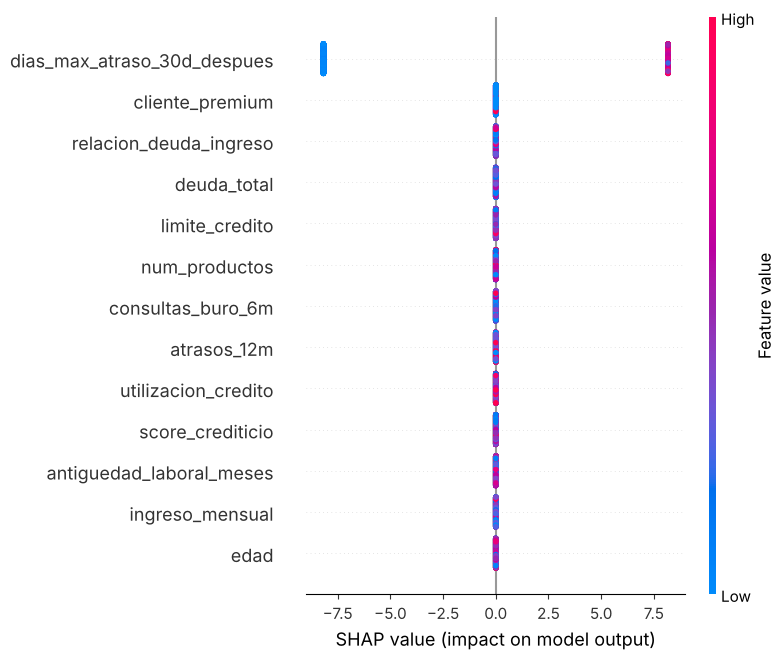

In [9]:
# Modelo XGBoost:

explainer = shap.TreeExplainer(xgb)

shap_values = explainer.shap_values(X_test)

shap.summary_plot(
    shap_values,
    X_test
)

## **Seleccionemos y analicemos un cliente en Particular:**

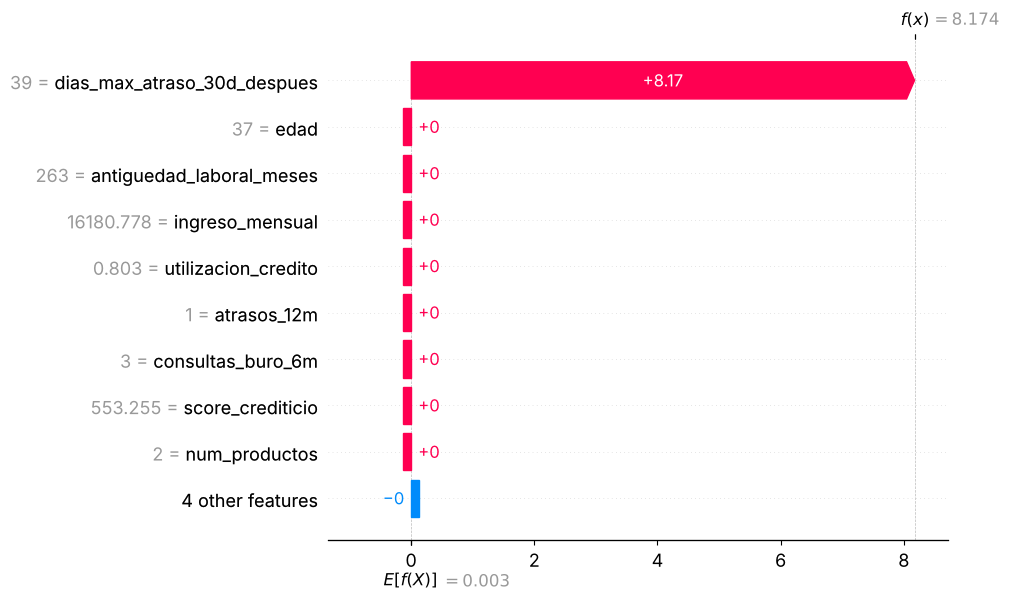

In [10]:
# Analicemos a un cliente en particular con XGBoost:

cliente = X_test.iloc[[11]]
shap_values_cliente = explainer.shap_values(cliente)

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_cliente[0],
        base_values=explainer.expected_value,
        data=cliente.iloc[0],
        feature_names=cliente.columns
    )
)

**Interpretación del gráfico:**

* El factor de riesgo principal (máximo días de atraso en alguno de sus pagos durante los 30 días siguientes a la evaluación) termina siendo determinante, lo que resulta en una predicción de riesgo final (en escala log-odds) de  f(x)=8.174  (muy por encima del promedio E[f(X)]=0.003). Así, si el umbral de aprobación fuera el estándar de 0.50, este cliente sería rechazado.

In [11]:
# Verificación del cliente analizado y de la composición del conjunto de prueba original:
n_sint = (X_test.index >= len(df)).sum()
print(f"Proporción de default en y_test original: {y_test.mean():.3f}   (proporción real: {y.mean():.3f})")
print(f"Registros sintéticos (creados por SMOTE) dentro de X_test: {n_sint} de {len(X_test)} ({n_sint/len(X_test):.1%})")
print(f"¿El 'cliente' analizado (fila 11, índice {X_test.index[11]}) es un registro sintético?:", X_test.index[11] >= len(df))

Proporción de default en y_test original: 0.499   (proporción real: 0.117)
Registros sintéticos (creados por SMOTE) dentro de X_test: 1162 de 2649 (43.9%)
¿El 'cliente' analizado (fila 11, índice 7659) es un registro sintético?: True


> **Hallazgo 8 – Interpretación de importancias y del cliente individual.**
> * En los tres modelos la variable más importante es `dias_max_atraso_30d_despues`, la misma que tiene la fuga. Las explicaciones describen al dato con fuga, no al riesgo del cliente.
> * El "cliente" que se analiza con SHAP **no es un cliente real**: es un registro generado por SMOTE (su índice es mayor que el número de filas del archivo). Cerca del 44% del conjunto de prueba original es sintético.
> * La interpretación mezcla escalas. f(x)=8.174 está en log-odds y equivale a una probabilidad de ≈0.9997. El valor base E[f(X)]≈0 corresponde a una probabilidad de 50%, que es la proporción artificial creada por SMOTE, no el 11.7% real.
> * Las importancias por impureza (`feature_importances_`) del árbol y del bosque tienden a favorecer variables continuas con muchos posibles cortes. Es más confiable usar importancia por permutación o SHAP calculados sobre datos de prueba reales.

# **Análisis desde la perspectiva del negocio:**

In [ ]:
GANANCIA_BUENO = 100
PERDIDA_DEFAULT = -500

In [13]:
# Función de utilidad:

# Considerando el umbral estándar:
threshold = 0.5

def utilidad(y_true, y_prob, threshold):

    aprobar = y_prob < threshold

    utilidad_total = 0

    for real, aprobado in zip(y_true, aprobar):

        if aprobado:

            if real == 0:
                utilidad_total += 100

            else:
                utilidad_total -= 500

    return utilidad_total



# Mejor modelo encontrado:
y_probs_mejor_modelo = y_probs[2]   # XGBoost

utilidad_05 = utilidad(
    y_test,
    y_probs_mejor_modelo,
    threshold=0.5
)

print("Mayor Utilidad (USD) con umbral 0.5:")
print(utilidad_05)

Mayor Utilidad (USD) con umbral 0.5:
132700


Mejor umbral: 0.01
Mayor Utilidad (USD): 132700


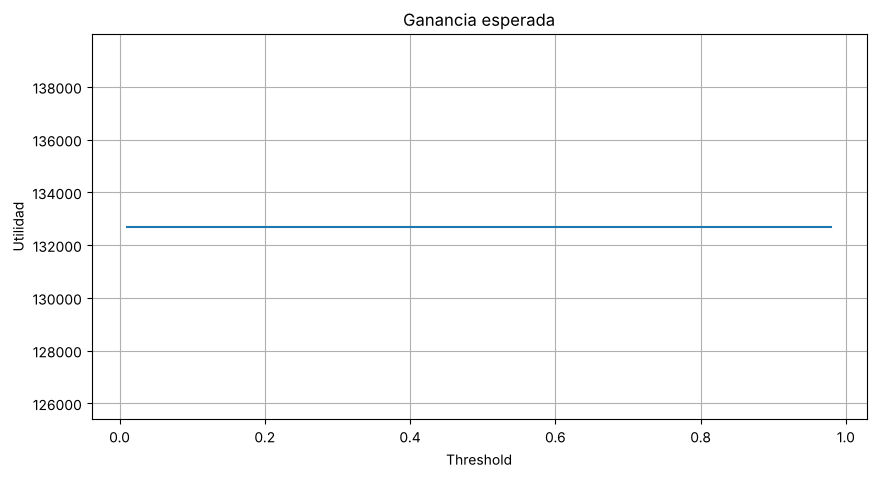

In [14]:
# Ajustando para buscar el mejor umbral óptimo:

thresholds = np.arange(
    0.01,
    0.99,
    0.01
)

utilidades = []

for th in thresholds:

    u = utilidad(
        y_test,
        y_probs_mejor_modelo,
        threshold=th
    )

    utilidades.append(u)

best_idx = np.argmax(utilidades)

best_threshold = thresholds[best_idx]

best_profit = utilidades[best_idx]

print('Mejor umbral:',best_threshold)
print('Mayor Utilidad (USD):',best_profit)



# Grafiquemos Umbral vs Utilidad:

plt.figure(figsize=(10,5))

plt.plot(
    thresholds,
    utilidades
)

plt.xlabel("Threshold")
plt.ylabel("Utilidad")
plt.title("Ganancia esperada")
plt.grid()

plt.show()

In [15]:
# Calculamos ahora la utilidad por cada 10,000 solicitudes:


def utilidad_por_10000(y_true, y_prob, threshold):

    aprobados = y_prob < threshold

    utilidad = 0
    total_aprobados = 0

    for real, aprobado in zip(y_true, aprobados):

        if aprobado:

            total_aprobados += 1

            if real == 0:
                utilidad += GANANCIA_BUENO

            else:
                utilidad += PERDIDA_DEFAULT

    # Escalamos a 10,000 solicitudes:
    utilidad_escalada = utilidad * (
        10_000 / len(y_true)
    )

    return utilidad_escalada



In [16]:
profit_default = utilidad_por_10000(
    y_test,
    y_probs_mejor_modelo,
    threshold=0.50
)

profit_optimal = utilidad_por_10000(
    y_test,
    y_probs_mejor_modelo,
    threshold=best_threshold
)

delta = profit_optimal - profit_default

incremento_pct = (
    delta /
    abs(profit_default)
) * 100

print(f"Threshold 0.50 : ${profit_default:,.0f}")
print(f"Threshold óptimo : ${profit_optimal:,.0f}")
print(f"Diferencia : ${delta:,.0f}")
print(f"Incremento : {incremento_pct:.1f}%")

Threshold 0.50 : $500,944
Threshold óptimo : $500,944
Diferencia : $0
Incremento : 0.0%


> **Hallazgo 9 – El análisis económico está sesgado.**
> * El umbral "óptimo" se busca **sobre el mismo conjunto de prueba** con el que después se reporta la utilidad, lo que la vuelve optimista. El umbral debe elegirse con datos de validación (por ejemplo, predicciones fuera de pliegue en validación cruzada) y el test se usa una sola vez para reportar.
> * Con la fuga, cualquier umbral da la misma utilidad (la curva es plana), así que el "umbral óptimo" de 0.01 no significa nada y el incremento reportado es 0%.
> * La utilidad por 10,000 solicitudes se escala desde un test con 50% de incumplimiento y registros sintéticos. La cifra de ≈ $500,944 USD no se puede trasladar al negocio real.
> * Además, `incremento_pct` divide entre `abs(profit_default)`, lo cual da porcentajes engañosos si la utilidad base es negativa o cercana a cero.

## **Matriz de Confusión**



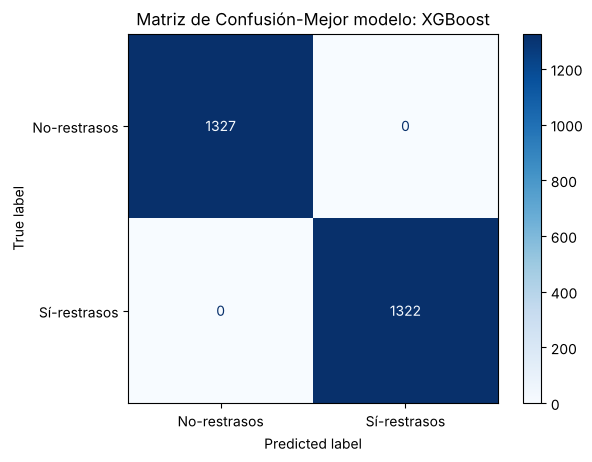

In [17]:
from sklearn.metrics import ConfusionMatrixDisplay

class_names = ["No-restrasos", "Sí-restrasos"]
y_pred = modelo.predict(X_test)

disp = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=class_names, cmap=plt.cm.Blues
)
plt.title(f"Matriz de Confusión-Mejor modelo: {nombre}")
plt.show()

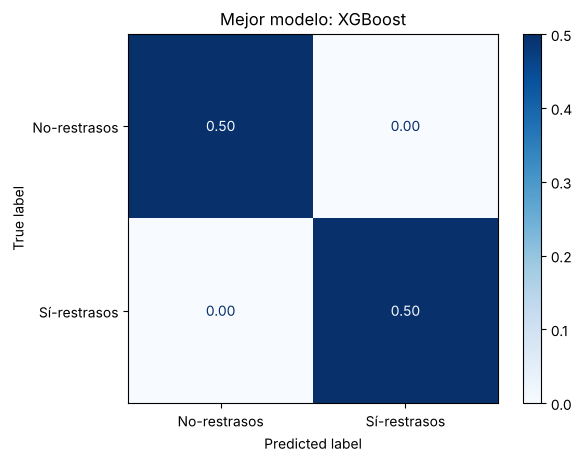

In [18]:
# O bien en su forma de proporciones:
disp = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=class_names,
    cmap=plt.cm.Blues,
    normalize='all',  # Normalizando con respecto al total de datos.
    values_format='.2f' # Total de decimales desplegadas.
)
plt.title(f"Mejor modelo: {nombre}")
plt.show()

> **Hallazgo 10 – La matriz de confusión no corresponde a un modelo elegido.**
> La celda usa las variables `modelo` y `nombre`, que son simplemente las que quedaron de la última vuelta del ciclo `for`. Sale XGBoost por el orden del diccionario, no porque se haya seleccionado. Además, se calcula con el umbral 0.5 y no con el umbral de negocio, y sobre el test balanceado artificialmente.

### **Resumen de hallazgos de la Parte I**

| # | Hallazgo | Tipo | Impacto |
|---|---|---|---|
| 1 | `dias_max_atraso_30d_despues` es información del futuro | Fuga en datos | Crítico: invalida todos los resultados |
| 2 | SMOTE antes de dividir train/test | Fuga en proceso | Crítico: test contaminado con sintéticos |
| 3 | Test con 50% de default y sin estratificar | Metodológico | Alto: métricas y utilidad irreales |
| 4 | Accuracy como única métrica con clases desbalanceadas | Conceptual | Alto |
| 5 | Verificación de sobreentrenamiento sobre datos contaminados | Metodológico | Alto |
| 6 | Sin ajuste de hiperparámetros ni validación cruzada | Metodológico | Medio |
| 7 | Selección de modelo sin criterio ("todos empatan") | Conceptual | Medio |
| 8 | Interpretación sobre la variable con fuga y un cliente sintético | Conceptual | Alto |
| 9 | Umbral optimizado sobre el test; utilidad escalada desde datos irreales | Fuga en proceso / negocio | Alto |
| 10 | Matriz de confusión con variable sobrante del ciclo | Error de código | Bajo-medio |

# **PARTE II – Solución corregida**

In [19]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             precision_score, recall_score, confusion_matrix,
                             RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from imblearn.pipeline import Pipeline as ImbPipeline
import warnings
warnings.filterwarnings("ignore")

## **1. Datos sin fuga y partición correcta**

* Se elimina `dias_max_atraso_30d_despues`.
* Se divide **primero** en entrenamiento (70%) y prueba (30%), estratificando por la variable objetivo para conservar el 11.7% de incumplimiento en ambos.
* El conjunto de prueba se guarda y solo se usa al final. Todo lo demás (hiperparámetros y umbral) se decide con validación cruzada dentro del entrenamiento.

In [20]:
VARIABLES_CON_FUGA = ["dias_max_atraso_30d_despues"]

X_c = df.drop(columns=[target] + VARIABLES_CON_FUGA)
y_c = df[target]

X_tr, X_te, y_tr, y_te = train_test_split(
    X_c, y_c,
    test_size=0.30,
    stratify=y_c,
    random_state=RANDOM_STATE
)

print("Entrenamiento:", X_tr.shape, f"| default: {y_tr.mean():.3f}")
print("Prueba:       ", X_te.shape, f"| default: {y_te.mean():.3f}")
print("Variables usadas:", list(X_c.columns))

Entrenamiento: (3500, 12) | default: 0.117
Prueba:        (1500, 12) | default: 0.117
Variables usadas: ['edad', 'ingreso_mensual', 'antiguedad_laboral_meses', 'score_crediticio', 'utilizacion_credito', 'atrasos_12m', 'consultas_buro_6m', 'num_productos', 'limite_credito', 'deuda_total', 'relacion_deuda_ingreso', 'cliente_premium']


## **2. Justificación de métricas y evidencia de sobreentrenamiento**

Primero entrenamos los mismos modelos del analista (valores por defecto), ya sin la fuga, para ver qué pasa con su métrica y con la brecha entre entrenamiento y prueba. Incluimos un clasificador trivial que predice "nadie incumple".

In [21]:
def resumen_metricas(modelo, Xa, ya, Xb, yb):
    p_a = modelo.predict_proba(Xa)[:, 1]
    p_b = modelo.predict_proba(Xb)[:, 1]
    return {
        "Accuracy train": accuracy_score(ya, (p_a >= 0.5).astype(int)),
        "Accuracy test":  accuracy_score(yb, (p_b >= 0.5).astype(int)),
        "ROC-AUC train":  roc_auc_score(ya, p_a),
        "ROC-AUC test":   roc_auc_score(yb, p_b),
        "PR-AUC test":    average_precision_score(yb, p_b),
        "Recall test (0.5)": recall_score(yb, (p_b >= 0.5).astype(int)),
    }

modelos_default = {
    "Árbol (por defecto)": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest (por defecto)": RandomForestClassifier(random_state=RANDOM_STATE),
    "XGBoost (por defecto)": XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE),
}
filas = {}
for nombre_m, m in modelos_default.items():
    m.fit(X_tr, y_tr)
    filas[nombre_m] = resumen_metricas(m, X_tr, y_tr, X_te, y_te)

filas["Trivial: 'nadie incumple'"] = {
    "Accuracy train": (y_tr == 0).mean(), "Accuracy test": (y_te == 0).mean(),
    "ROC-AUC train": 0.5, "ROC-AUC test": 0.5,
    "PR-AUC test": y_te.mean(), "Recall test (0.5)": 0.0,
}
tabla_default = pd.DataFrame(filas).T.round(3)
tabla_default

,Accuracy train,Accuracy test,ROC-AUC train,ROC-AUC test,PR-AUC test,Recall test (0.5)
Árbol (por defecto),1.000,0.833,1.0,0.635,0.193,0.375
Random Forest (por defecto),1.000,0.886,1.0,0.777,0.369,0.125
XGBoost (por defecto),0.999,0.883,1.0,0.769,0.335,0.227
Trivial: 'nadie incumple',0.883,0.883,0.5,0.500,0.117,0.000


**Lectura:**

* **Sobreentrenamiento claro.** El árbol por defecto llega a accuracy y ROC-AUC de 1.0 en entrenamiento, pero en prueba su ROC-AUC baja a ~0.6. Memorizó los datos. El Random Forest y el XGBoost por defecto también tienen una brecha grande entre entrenamiento y prueba.
* **El accuracy engaña.** El clasificador trivial tiene 88.3% de accuracy sin detectar a un solo cliente que incumple (recall = 0). El árbol por defecto queda incluso *por debajo* del trivial en accuracy, y Random Forest y XGBoost prácticamente lo igualan. Además, con umbral 0.5 detectan solo entre 12% y 23% de los incumplimientos. Con accuracy parecería que ningún modelo sirve, cuando en realidad sí ordenan bien el riesgo (ROC-AUC ~0.77).
* Por eso usamos como métrica principal de ajuste la **PR-AUC (Average Precision)**, que mide qué tan bien se identifica a la clase minoritaria. Como apoyo reportamos **ROC-AUC** (capacidad de ordenar por riesgo) y **Brier score** (calidad de la probabilidad). La decisión final se toma con la **utilidad económica**.

## **3. Ajuste de hiperparámetros con validación cruzada**

* Validación cruzada estratificada de 5 pliegues **solo sobre el entrenamiento**, optimizando PR-AUC.
* Se regulariza la complejidad (profundidad, tamaño mínimo de hoja, número de variables por corte, tasa de aprendizaje).
* Para el desbalance se prueba, como hiperparámetro, ponderar la clase minoritaria (`class_weight` / `scale_pos_weight`) en lugar de generar datos sintéticos.

In [22]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
spw = (y_tr == 0).sum() / (y_tr == 1).sum()   # peso para la clase minoritaria en XGBoost

busquedas = {
    "Árbol de Decisión": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"max_depth": [3, 4, 5, 6, 8],
         "min_samples_leaf": [10, 25, 50, 100],
         "class_weight": [None, "balanced"]}),
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        {"n_estimators": [300],
         "max_depth": [4, 6, 8, None],
         "min_samples_leaf": [5, 20, 50],
         "max_features": ["sqrt", 0.5],
         "class_weight": [None, "balanced"]}),
    "XGBoost": (
        XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1),
        {"n_estimators": [200, 400],
         "max_depth": [2, 3, 4],
         "learning_rate": [0.03, 0.1],
         "subsample": [0.8],
         "colsample_bytree": [0.8],
         "min_child_weight": [1, 5],
         "scale_pos_weight": [1, spw]}),
}

mejores = {}
resultados_cv = {}
for nombre_m, (est, grid) in busquedas.items():
    gs = GridSearchCV(est, grid, scoring="average_precision", cv=cv,
                      n_jobs=-1, return_train_score=True)
    gs.fit(X_tr, y_tr)
    mejores[nombre_m] = gs.best_estimator_
    i = gs.best_index_
    resultados_cv[nombre_m] = {
        "PR-AUC CV train": gs.cv_results_["mean_train_score"][i],
        "PR-AUC CV validación": gs.best_score_,
    }
    print(f"{nombre_m}: {gs.best_params_}")

Árbol de Decisión: {'class_weight': None, 'max_depth': 4, 'min_samples_leaf': 25}


Random Forest: {'class_weight': None, 'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 50, 'n_estimators': 300}


XGBoost: {'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 200, 'scale_pos_weight': 1, 'subsample': 0.8}


In [23]:
# Desempeño final en el conjunto de prueba (solo se usa aquí para reportar):
probs_te = {n: m.predict_proba(X_te)[:, 1] for n, m in mejores.items()}

tabla = {}
for n, m in mejores.items():
    p_tr = m.predict_proba(X_tr)[:, 1]
    p_te = probs_te[n]
    tabla[n] = {
        **resultados_cv[n],
        "Brecha CV (train - val)": resultados_cv[n]["PR-AUC CV train"] - resultados_cv[n]["PR-AUC CV validación"],
        "ROC-AUC train": roc_auc_score(y_tr, p_tr),
        "ROC-AUC test": roc_auc_score(y_te, p_te),
        "PR-AUC test": average_precision_score(y_te, p_te),
        "Brier test": brier_score_loss(y_te, p_te),
    }
tabla_modelos = pd.DataFrame(tabla).T.round(3)
tabla_modelos

,PR-AUC CV train,PR-AUC CV validación,Brecha CV (train - val),ROC-AUC train,ROC-AUC test,PR-AUC test,Brier test
Árbol de Decisión,0.442,0.372,0.070,0.805,0.764,0.333,0.091
Random Forest,0.498,0.428,0.070,0.872,0.805,0.386,0.086
XGBoost,0.527,0.434,0.093,0.849,0.814,0.426,0.084


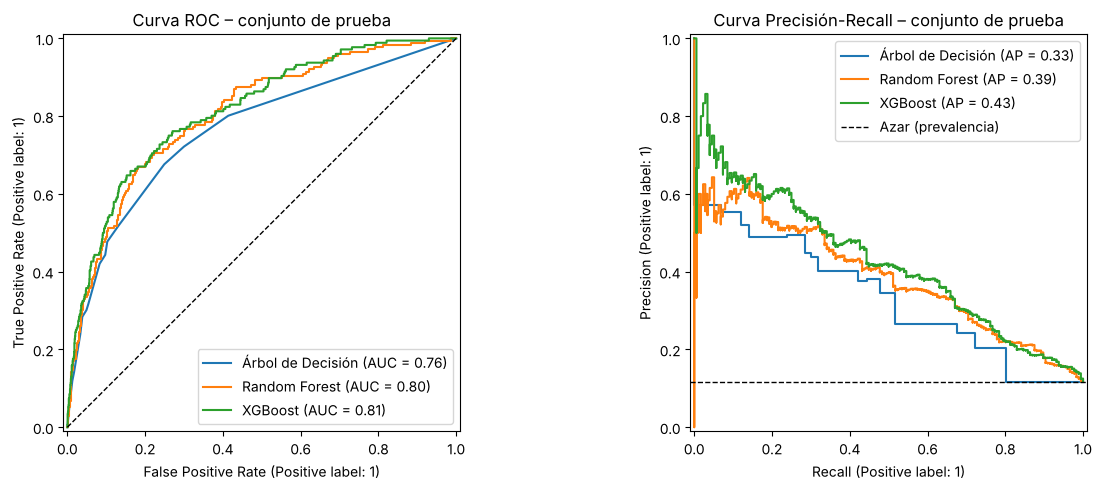

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for n, p in probs_te.items():
    RocCurveDisplay.from_predictions(y_te, p, name=n, ax=ax[0])
    PrecisionRecallDisplay.from_predictions(y_te, p, name=n, ax=ax[1])
ax[0].plot([0, 1], [0, 1], "k--", lw=1)
ax[1].axhline(y_te.mean(), color="k", ls="--", lw=1, label="Azar (prevalencia)")
ax[0].set_title("Curva ROC – conjunto de prueba")
ax[1].set_title("Curva Precisión-Recall – conjunto de prueba")
ax[1].legend()
plt.tight_layout(); plt.show()

**Lectura:**

* Ya sin la fuga, los resultados son realistas. Los tres modelos ajustados tienen ROC-AUC en prueba entre ~0.76 y ~0.81, y PR-AUC entre ~0.33 y ~0.43 (frente a 0.117 de un modelo al azar).
* **XGBoost** tiene el mejor desempeño en las tres métricas de prueba (ROC-AUC, PR-AUC y Brier). Random Forest queda cerca, y el árbol individual es claramente inferior.
* **Sub/sobreentrenamiento.** Después de regularizar, la brecha entre entrenamiento y validación en PR-AUC es moderada (~0.07 – 0.09) y el desempeño en prueba es consistente con el de validación cruzada. Hay un ligero sobreajuste, esperable en ensambles de árboles, pero ya no es el sobreentrenamiento extremo del árbol sin restricciones. No hay subentrenamiento: los tres modelos superan con amplitud al azar y al modelo trivial.
* En la búsqueda, la mejor opción fue **no** reponderar las clases. Esto mantiene las probabilidades bien calibradas, lo cual es importante para elegir el umbral con criterio económico.

### **¿Y SMOTE aplicado correctamente?**

Para no descartar SMOTE sin evidencia, lo aplicamos de la forma correcta: dentro de un `Pipeline` de `imblearn`, de modo que en cada pliegue solo se generan sintéticos con los datos de entrenamiento de ese pliegue. Usamos los mismos hiperparámetros del mejor XGBoost.

In [25]:
xgb_params = mejores["XGBoost"].get_params()
pipe_smote = ImbPipeline([
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("xgb", XGBClassifier(**xgb_params)),
])

from sklearn.model_selection import cross_val_score
ap_cv_smote = cross_val_score(pipe_smote, X_tr, y_tr, cv=cv, scoring="average_precision").mean()
pipe_smote.fit(X_tr, y_tr)
p_smote = pipe_smote.predict_proba(X_te)[:, 1]

comp = pd.DataFrame({
    "XGBoost sin SMOTE": [tabla_modelos.loc["XGBoost", "PR-AUC CV validación"],
                          roc_auc_score(y_te, probs_te["XGBoost"]),
                          average_precision_score(y_te, probs_te["XGBoost"]),
                          brier_score_loss(y_te, probs_te["XGBoost"]),
                          probs_te["XGBoost"].mean()],
    "XGBoost + SMOTE (en pipeline)": [ap_cv_smote, roc_auc_score(y_te, p_smote),
                                      average_precision_score(y_te, p_smote),
                                      brier_score_loss(y_te, p_smote), p_smote.mean()],
}, index=["PR-AUC CV validación", "ROC-AUC test", "PR-AUC test", "Brier test",
          "Prob. media predicha (real = 0.117)"]).round(3)
comp

,XGBoost sin SMOTE,XGBoost + SMOTE (en pipeline)
PR-AUC CV validación,0.434,0.355
ROC-AUC test,0.814,0.767
PR-AUC test,0.426,0.321
Brier test,0.084,0.172
Prob. media predicha (real = 0.117),0.119,0.376


**Lectura:** SMOTE bien aplicado no ayuda en este problema: empeora la PR-AUC (en validación cruzada y en prueba) y la ROC-AUC, y distorsiona mucho las probabilidades. El modelo con SMOTE predice en promedio un riesgo de ~38%, cuando el real es 11.7%, y el Brier se duplica. Como la decisión de negocio se toma con un umbral sobre la probabilidad, es preferible no sobremuestrear y manejar el desbalance con el umbral.

## **4. Umbral de clasificación y utilidad económica**

**Umbral teórico.** Si las probabilidades están bien calibradas, aprobar a un cliente con probabilidad de incumplimiento $p$ tiene utilidad esperada

$$E[U] = 100\,(1-p) - 500\,p,$$

que es positiva cuando $p < 100/600 \approx 0.167$. Es decir, el umbral de 0.5 es demasiado permisivo para esta estructura de costos: aprueba clientes con hasta 50% de probabilidad de incumplir, cuando cada uno de ellos destruye valor a partir de 16.7%.

**Umbral empírico.** Lo elegimos con las predicciones *fuera de pliegue* (out-of-fold) de la validación cruzada en entrenamiento. Así el conjunto de prueba no participa en la decisión. Después reportamos en prueba la utilidad con: (a) aprobar a todos (sin modelo), (b) umbral 0.5 y (c) umbral optimizado.

Umbral óptimo (elegido con validación cruzada en entrenamiento):
  Árbol de Decisión: 0.13
  Random Forest: 0.18
  XGBoost: 0.17
Umbral teórico de equilibrio: 0.167


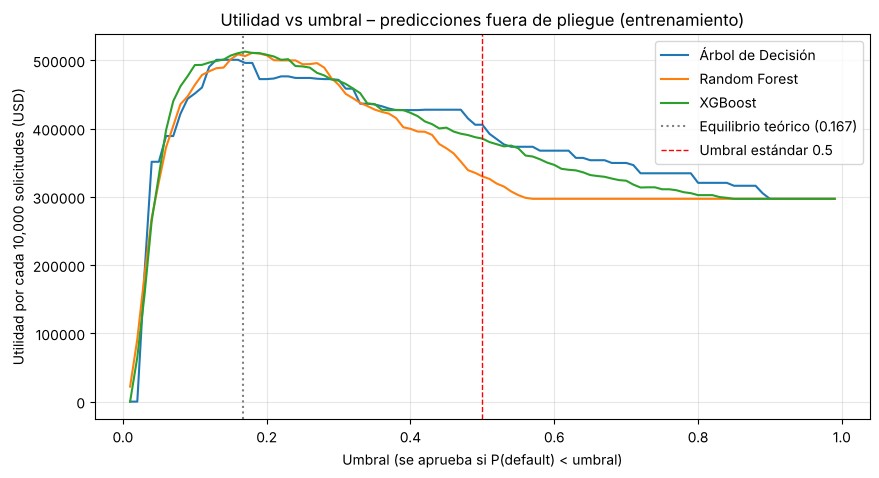

In [26]:
def utilidad_vec(y_true, y_prob, threshold):
    # Se aprueba si la probabilidad de default es menor al umbral.
    y_true = np.asarray(y_true)
    aprobar = np.asarray(y_prob) < threshold
    return GANANCIA_BUENO * np.sum(aprobar & (y_true == 0)) + PERDIDA_DEFAULT * np.sum(aprobar & (y_true == 1))

umbrales = np.round(np.arange(0.01, 1.00, 0.01), 2)
umbral_opt, curvas_oof = {}, {}

for n, m in mejores.items():
    p_oof = cross_val_predict(m, X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]
    u = np.array([utilidad_vec(y_tr, p_oof, t) for t in umbrales])
    curvas_oof[n] = u * 10_000 / len(y_tr)
    umbral_opt[n] = umbrales[np.argmax(u)]

print("Umbral óptimo (elegido con validación cruzada en entrenamiento):")
for n, t in umbral_opt.items():
    print(f"  {n}: {t:.2f}")
print(f"Umbral teórico de equilibrio: {100/600:.3f}")

plt.figure(figsize=(10, 5))
for n, c in curvas_oof.items():
    plt.plot(umbrales, c, label=n)
plt.axvline(100/600, color="gray", ls=":", label="Equilibrio teórico (0.167)")
plt.axvline(0.5, color="red", ls="--", lw=1, label="Umbral estándar 0.5")
plt.xlabel("Umbral (se aprueba si P(default) < umbral)")
plt.ylabel("Utilidad por cada 10,000 solicitudes (USD)")
plt.title("Utilidad vs umbral – predicciones fuera de pliegue (entrenamiento)")
plt.legend(); plt.grid(alpha=.3); plt.show()

In [27]:
# Evaluación final en el conjunto de prueba (con la proporción real de default):
k = 10_000 / len(y_te)
filas = []
for n, p in probs_te.items():
    t = umbral_opt[n]
    filas.append({
        "Modelo": n,
        "Umbral óptimo": t,
        "Utilidad test, umbral 0.5": utilidad_vec(y_te, p, 0.5),
        "Utilidad test, umbral óptimo": utilidad_vec(y_te, p, t),
        "Por 10k: sin modelo (aprobar a todos)": utilidad_vec(y_te, p, 1.01) * k,
        "Por 10k: umbral 0.5": utilidad_vec(y_te, p, 0.5) * k,
        "Por 10k: umbral óptimo": utilidad_vec(y_te, p, t) * k,
        "% aprobados (óptimo)": 100 * np.mean(p < t),
    })
tabla_negocio = pd.DataFrame(filas).set_index("Modelo")
tabla_negocio["Ganancia vs 0.5 (por 10k)"] = tabla_negocio["Por 10k: umbral óptimo"] - tabla_negocio["Por 10k: umbral 0.5"]
tabla_negocio["Ganancia vs sin modelo (por 10k)"] = tabla_negocio["Por 10k: umbral óptimo"] - tabla_negocio["Por 10k: sin modelo (aprobar a todos)"]
pd.options.display.float_format = "{:,.2f}".format
tabla_negocio.T

Modelo,Árbol de Decisión,Random Forest,XGBoost
Umbral óptimo,0.13,0.18,0.17
"Utilidad test, umbral 0.5","61,000.00","48,500.00","56,700.00"
"Utilidad test, umbral óptimo","72,600.00","77,900.00","80,300.00"
Por 10k: sin modelo (aprobar a todos),"296,000.00","296,000.00","296,000.00"
Por 10k: umbral 0.5,"406,666.67","323,333.33","378,000.00"
Por 10k: umbral óptimo,"484,000.00","519,333.33","535,333.33"
% aprobados (óptimo),82.40,78.73,79.13
Ganancia vs 0.5 (por 10k),"77,333.33","196,000.00","157,333.33"
Ganancia vs sin modelo (por 10k),"188,000.00","223,333.33","239,333.33"


Umbral 0.5:
   Aprobados: 1455 (97.0%) | buenos aprobados: 1307 | defaults aprobados: 148
   Rechazados: 45 | defaults evitados: 28 | buenos rechazados (venta perdida): 17
   Recall de defaults: 15.9% | Precisión al rechazar: 62.2%
   Tasa de default en la cartera aprobada: 10.2%  (sin modelo: 11.7%)

Umbral óptimo 0.17:
   Aprobados: 1187 (79.1%) | buenos aprobados: 1123 | defaults aprobados: 64
   Rechazados: 313 | defaults evitados: 112 | buenos rechazados (venta perdida): 201
   Recall de defaults: 63.6% | Precisión al rechazar: 35.8%
   Tasa de default en la cartera aprobada: 5.4%  (sin modelo: 11.7%)



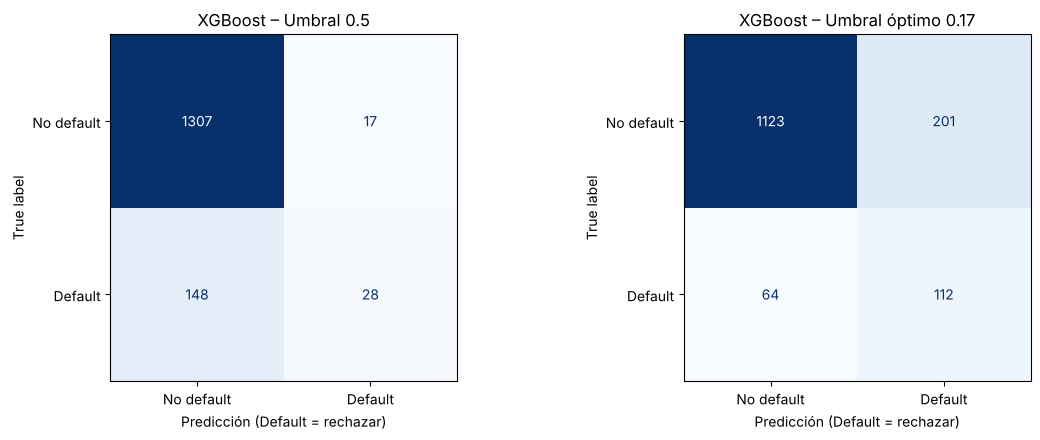

In [28]:
# Detalle del modelo seleccionado:
mejor = "XGBoost"
p_best = probs_te[mejor]
t_best = umbral_opt[mejor]

for etiqueta, t in [("Umbral 0.5", 0.5), (f"Umbral óptimo {t_best:.2f}", t_best)]:
    rechazar = (p_best >= t).astype(int)   # 1 = se predice default / se rechaza
    tn, fp, fn, tp = confusion_matrix(y_te, rechazar).ravel()
    print(f"{etiqueta}:")
    print(f"   Aprobados: {tn+fn} ({(tn+fn)/len(y_te):.1%}) | buenos aprobados: {tn} | defaults aprobados: {fn}")
    print(f"   Rechazados: {tp+fp} | defaults evitados: {tp} | buenos rechazados (venta perdida): {fp}")
    print(f"   Recall de defaults: {tp/(tp+fn):.1%} | Precisión al rechazar: {tp/(tp+fp):.1%}")
    print(f"   Tasa de default en la cartera aprobada: {fn/(tn+fn):.1%}  (sin modelo: {y_te.mean():.1%})\n")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, (etiqueta, t) in zip(ax, [("Umbral 0.5", 0.5), (f"Umbral óptimo {t_best:.2f}", t_best)]):
    ConfusionMatrixDisplay.from_predictions(
        y_te, (p_best >= t).astype(int),
        display_labels=["No default", "Default"], cmap=plt.cm.Blues, ax=a, colorbar=False)
    a.set_title(f"{mejor} – {etiqueta}")
    a.set_xlabel("Predicción (Default = rechazar)")
plt.tight_layout(); plt.show()

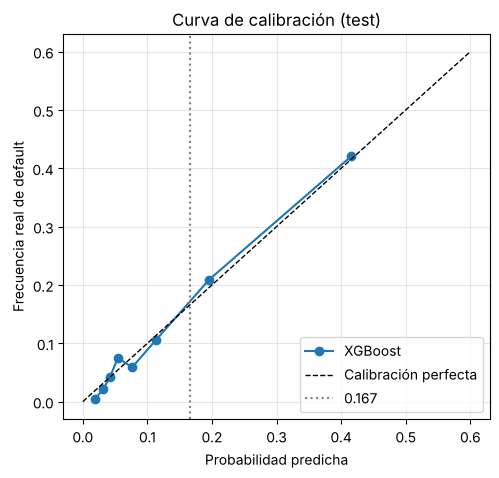

In [29]:
# Calibración del modelo seleccionado (¿la probabilidad predicha se parece a la frecuencia real?):
frac_pos, prob_media = calibration_curve(y_te, p_best, n_bins=8, strategy="quantile")
plt.figure(figsize=(5.5, 5))
plt.plot(prob_media, frac_pos, "o-", label=mejor)
plt.plot([0, 0.6], [0, 0.6], "k--", lw=1, label="Calibración perfecta")
plt.axvline(100/600, color="gray", ls=":", label="0.167")
plt.xlabel("Probabilidad predicha"); plt.ylabel("Frecuencia real de default")
plt.title("Curva de calibración (test)"); plt.legend(); plt.grid(alpha=.3); plt.show()

**Lectura del impacto del umbral:**

* Con XGBoost y el **umbral estándar de 0.5** se aprueba al 97% de los solicitantes y solo se detecta 16% de los incumplimientos. La utilidad mejora algo respecto a no usar modelo, pero se desaprovecha casi todo su valor.
* Con el **umbral optimizado (0.17)**, elegido sin usar el conjunto de prueba y prácticamente igual al umbral teórico de 1/6, se rechaza a ~21% de los solicitantes. Se evitan cerca de 64% de los incumplimientos y la tasa de default de la cartera aprobada baja de 11.7% a 5.4%, a cambio de perder algunas ventas de clientes buenos. Como un incumplimiento cuesta lo mismo que cinco clientes buenos, el intercambio conviene.
* La curva de calibración muestra que las probabilidades de XGBoost se aproximan razonablemente a la frecuencia real. Por eso el umbral teórico y el empírico coinciden.
* La curva de utilidad es relativamente plana entre ~0.12 y ~0.23 (varía menos de 3%), así que el resultado no depende de un valor exacto del umbral. Esto da margen operativo.

## **5. Selección del modelo**

Se elige **XGBoost** (regularizado: árboles de profundidad 2, tasa de aprendizaje 0.03, 200 árboles, submuestreo de filas y columnas):

* Mejor desempeño en prueba en ROC-AUC, PR-AUC y Brier.
* Mayor utilidad económica con el umbral optimizado.
* Brecha entre entrenamiento y validación moderada, y desempeño en prueba consistente con la validación cruzada.
* Con árboles poco profundos y SHAP se puede explicar cada decisión, lo cual es necesario para dar razones de rechazo a un cliente y para la supervisión regulatoria.

Random Forest es una alternativa cercana. El árbol de decisión individual es el más fácil de explicar, pero deja una utilidad claramente menor.

## **6. Factores más importantes del modelo seleccionado**

In [30]:
xgb_final = mejores["XGBoost"]
explainer_c = shap.TreeExplainer(xgb_final)
shap_te = explainer_c.shap_values(X_te)

imp_shap = pd.Series(np.abs(shap_te).mean(axis=0), index=X_te.columns).sort_values(ascending=False)

perm = permutation_importance(xgb_final, X_te, y_te, scoring="average_precision",
                              n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
imp_perm = pd.Series(perm.importances_mean, index=X_te.columns)

pd.options.display.float_format = "{:,.4f}".format
pd.DataFrame({"SHAP medio |valor| (log-odds)": imp_shap,
              "Permutación (caída en PR-AUC)": imp_perm[imp_shap.index]})

,SHAP medio |valor| (log-odds),Permutación (caída en PR-AUC)
utilizacion_credito,0.5037,0.1564
consultas_buro_6m,0.4644,0.0986
score_crediticio,0.4615,0.1123
relacion_deuda_ingreso,0.2328,0.0303
atrasos_12m,0.1339,0.0142
antiguedad_laboral_meses,0.0547,0.0002
num_productos,0.0356,-0.0001
deuda_total,0.0279,-0.0009
ingreso_mensual,0.0278,-0.0011
edad,0.0115,-0.0017


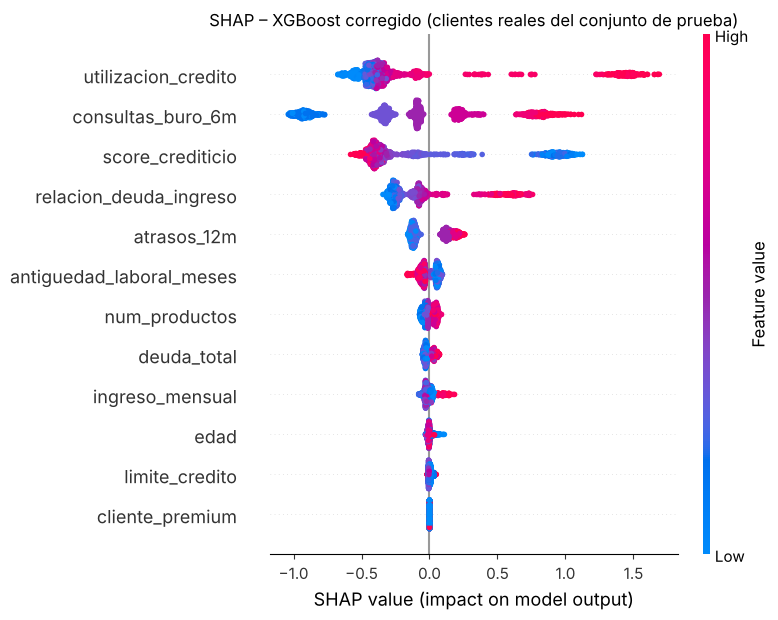

In [31]:
shap.summary_plot(shap_te, X_te, show=False)
plt.title("SHAP – XGBoost corregido (clientes reales del conjunto de prueba)")
plt.tight_layout(); plt.show()

**Interpretación de negocio de los factores principales** (SHAP y permutación coinciden en las mismas cuatro variables; solo cambia el orden entre el 2.º y el 3.º):

1. **`utilizacion_credito` – qué tanto usa el cliente de sus líneas disponibles.** Es el factor más importante con ambos métodos. Valores altos (cercanos a 1) aumentan el riesgo. Un cliente que ya agotó su crédito tiene poco margen para absorber un imprevisto y suele estar financiando gastos corrientes con deuda.
2. **`consultas_buro_6m` – búsqueda reciente de crédito.** Muchas consultas al buró en seis meses indican que el cliente está pidiendo crédito en varias instituciones, típico de alguien con necesidad urgente de liquidez. Es una señal temprana de estrés financiero.
3. **`score_crediticio` – historial.** Un score alto reduce el riesgo. Resume el comportamiento de pago acumulado y es el principal factor protector.
4. **`relacion_deuda_ingreso` – apalancamiento.** A mayor deuda respecto al ingreso, mayor riesgo, porque queda menos capacidad de pago ante cualquier choque. Pesa menos que las tres anteriores. Parte de su efecto puede estar repartido con `deuda_total` e `ingreso_mensual`, de las que es redundante.

Le sigue `atrasos_12m` (atrasos del último año). Destaca también lo que **no** pesa: la edad, el ingreso, la antigüedad laboral y el segmento premium casi no aportan. En particular, ser cliente premium no implica menor riesgo (la tasa de default es prácticamente la misma en ambos segmentos), lo cual es relevante si hoy se dan condiciones preferentes a ese segmento.

### **Ejemplo de explicación individual (cliente real)**

Índice original del cliente: 3785 | P(default) = 0.294 | Default real: 1


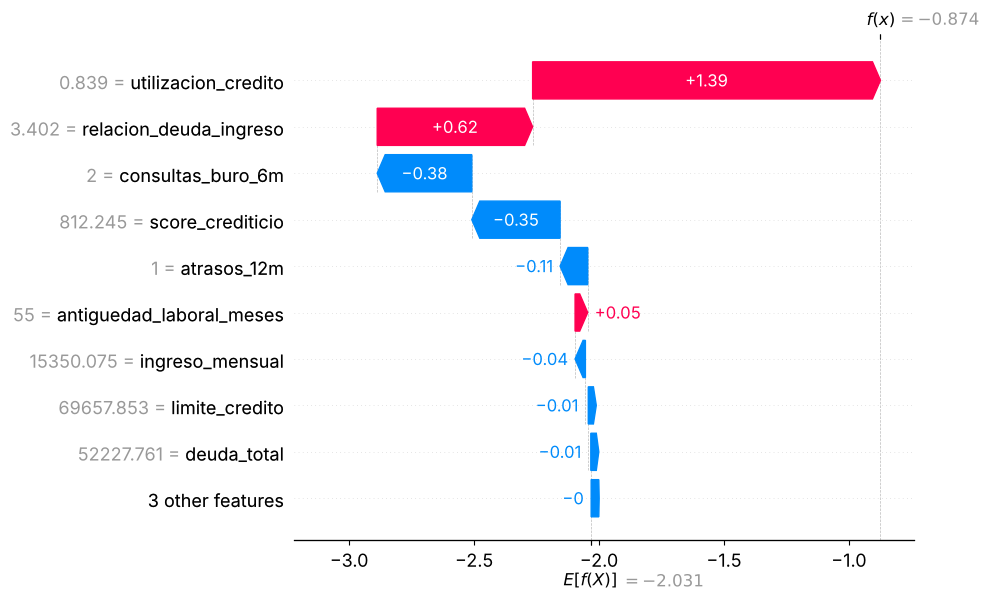

Valor base E[f(X)] = -2.031 log-odds  ->  0.116 de probabilidad


In [32]:
# Tomamos un cliente REAL del conjunto de prueba que el modelo rechazaría con el umbral óptimo
# y que efectivamente incumplió:
candidatos = np.where((p_best >= t_best) & (y_te.values == 1))[0]
idx = candidatos[0]
cliente_c = X_te.iloc[[idx]]
print(f"Índice original del cliente: {X_te.index[idx]} | P(default) = {p_best[idx]:.3f} | Default real: {y_te.iloc[idx]}")

sv = explainer_c.shap_values(cliente_c)
shap.plots.waterfall(shap.Explanation(values=sv[0], base_values=explainer_c.expected_value,
                                      data=cliente_c.iloc[0], feature_names=cliente_c.columns))

sigm = lambda z: 1 / (1 + np.exp(-z))
print(f"Valor base E[f(X)] = {explainer_c.expected_value:.3f} log-odds  ->  {sigm(explainer_c.expected_value):.3f} de probabilidad")

**Interpretación:** el gráfico parte del riesgo base del modelo, −2.03 en log-odds, que equivale a 11.6% de probabilidad (prácticamente la tasa real de la cartera, a diferencia del 50% artificial del cuaderno original). Después muestra cuánto suma o resta cada característica de este cliente. Su probabilidad final de incumplimiento es 0.29: se rechazaría con el umbral de 0.17, mientras que con el umbral de 0.5 se habría aprobado, y este cliente efectivamente incumplió. Este tipo de explicación es el que se puede comunicar a un analista de crédito o al propio cliente como motivo de rechazo.

# **Conclusiones particulares:**



**Incluye un reporte de los resultados obtenidos dirigido al CEO de la fintech con las sugerencias y conclusiones en relación a cuál modelo desplegar.**

### +++++++++++ Inicia sección de Conclusiones Particulares ++++++++++++++++

Resultado de la auditoría del modelo de riesgo de incumplimiento a 90 días

**Recomendación: no desplegar el modelo propuesto por el analista junior.** Sí se recomienda avanzar con la versión corregida (XGBoost regularizado con umbral de 0.17), mediante una prueba piloto controlada.

**1. Por qué el modelo original no puede usarse.**
El modelo original reporta 100% de aciertos, y eso no es posible en riesgo de crédito. El resultado se explica por un error en los datos: una de las variables (`dias_max_atraso_30d_despues`) registra los atrasos del cliente en los 30 días *posteriores* a la evaluación. Es decir, el modelo "veía el futuro". En producción ese dato no existe al momento de decidir, por lo que el desempeño real sería muy distinto al reportado. A esto se suman otros problemas: datos inventados por la técnica de balanceo dentro de la prueba, una métrica que no sirve para este problema, y un umbral y una utilidad calculados sobre una cartera con 50% de incumplimientos, cuando la real tiene 11.7%. La utilidad que se presentó (~$500 mil USD por cada 10,000 solicitudes) no es alcanzable.

**2. Qué se puede esperar de un modelo correcto.**
Al quitar la variable con fuga y rehacer el proceso correctamente, el mejor modelo (XGBoost) ordena bien a los clientes por riesgo (ROC-AUC ≈ 0.81), aunque obviamente no es perfecto. En términos de negocio, por cada 10,000 solicitudes evaluadas:

| Escenario | Utilidad estimada (USD) |
|---|---|
| Sin modelo (aprobar a todos) | ≈ $296,000 |
| Modelo con umbral estándar 0.5 | ≈ $378,000 |
| **Modelo con umbral optimizado 0.17** | **≈ $535,000** |

El umbral optimizado aporta ≈ **$157,000 adicionales** frente al umbral 0.5 (+42%) y ≈ **$239,000** frente a no usar modelo (+81%). Se rechazaría a cerca del 21% de los solicitantes y la tasa de incumplimiento de la cartera aprobada bajaría de 11.7% a alrededor de 5.4%.

La razón es sencilla: como un incumplimiento cuesta lo mismo que la ganancia de cinco clientes buenos, conviene rechazar a cualquier solicitante con más de ~17% de probabilidad de incumplir, no solo a los que superan el 50%.

**3. Qué factores explican el riesgo.** En orden de importancia: el uso de las líneas de crédito disponibles, el número de consultas recientes al buró (búsqueda urgente de crédito), el score crediticio y la relación deuda/ingreso. La edad, la antigüedad laboral y el segmento premium casi no influyen. Ser cliente premium **no** implica menor riesgo.

**4. Recomendaciones antes y durante el despliegue.**
1. Eliminar del proceso de datos cualquier variable posterior a la fecha de evaluación, y documentar para cada variable en qué momento está disponible.
2. Validar el modelo con datos de un periodo posterior (validación fuera de tiempo), ya que todos los datos actuales pertenecen al mismo periodo histórico.
3. Hacer un piloto: aplicar el modelo en paralelo a la política actual (o a una parte de las solicitudes) durante 2 o 3 meses y comparar resultados reales.
4. Revisar el umbral si cambian la ganancia por buen cliente o la pérdida por incumplimiento. El umbral se calcula como ganancia / (ganancia + pérdida).
5. Monitorear mensualmente la calibración, la tasa de incumplimiento de los aprobados y la estabilidad de las variables. Reentrenar cuando se detecten desviaciones.
6. Revisar que el modelo no genere un trato discriminatorio, por ejemplo por edad, y que permita dar razones claras de rechazo con las explicaciones SHAP.
7. Que el código de producción pase por revisión de pares antes de su despliegue. El error de la matriz de confusión del cuaderno original muestra que hace falta.

### +++++++++++ Termina sección de conclusiones particulares ++++++++++++++

# **Conclusiones**

Incluye todos los comentarios y conclusiones de esta actividad. En particular, responde sobre los siguientes puntos:

* Indica en qué casos el uso de LLMs fue de mayor provecho.
* En cuáles casos tu intervención como experto en combinación con los LLM fue importante para alcanzar con los objetivos propuestos.


### +++++++++++ Inicia sección de Conclusiones Finales ++++++++++++++++

**Comentarios generales.** La actividad muestra que un modelo con métricas perfectas puede ser el más peligroso de desplegar. Los tres errores que más pesan en el resultado son la variable con información del futuro, el balanceo de clases antes de dividir los datos y la optimización del umbral sobre el conjunto de prueba. Los tres son formas de fuga de información y ninguno produce un error de ejecución. El código corre sin problemas y los números se ven bien, así que solo se detectan con criterio y entendiendo el negocio. Una vez corregidos, la diferencia entre umbral 0.5 y umbral de negocio pesa más en la utilidad que la diferencia entre los tres algoritmos.

**Uso de herramientas de IA generativa.**

* **Herramienta utilizada:** Claude (Anthropic), modelo Opus 5.5, en la aplicación de Claude. 
* **Dónde fue de mayor provecho el LLM:**
  * Revisión rápida del código original para enumerar errores metodológicos.
  * Aclaración de conceptos y objetivos especificos y finales en orden de importancia para resolverlos juntos.
  * Verificaciones puntuales y correcciones sobre propuestas erroneas.
  * Propuesta de estructura del reporte al CEO con los puntos importantes a mencionar.
* **Dónde fue importante la intervención como experto:** Asegurarse de que cada uno de los errores metodológicos en la parte 1 se resolvieran. Proponer las métricas que mejor funcionaban al negocio. Comprobar que el umbral tuvieran sentido para que el CEO vea una mejora económica. Lo más importante fue, elegir el modelo a desplegar ya que el desempeño de este es quien iba a estar encargado de dar las insights para que el negocio pudiera tener mejores resultados. Y finalmente comprobar que los resultados tengan sentido.

### +++++++++++ Termina sección de conclusiones finales ++++++++++++++

# **<<< Fin de la Actividad de la Semana - Modelos de Árboles >>>**